## Ans 1

In [1]:
import re, nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
for p in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(p, quiet=True)

paragraph = ("Cricket is more than just a sport for me, it is an emotion that connects millions of fans across the world. "
             "I still remember watching the 2011 World Cup final with my family, and the roar of the crowd gave me goosebumps. "
             "Batsmen like Virat Kohli play with so much passion and discipline that every match feels like a story. "
             "Bowlers work hard to craft clever spells, and a single wicket can change the entire game in minutes. "
             "Playing cricket with my friends in the evening is the best way to relax after a long day of studies. "
             "This amazing game teaches teamwork, patience, and the courage to never give up.")
print(paragraph)

Cricket is more than just a sport for me, it is an emotion that connects millions of fans across the world. I still remember watching the 2011 World Cup final with my family, and the roar of the crowd gave me goosebumps. Batsmen like Virat Kohli play with so much passion and discipline that every match feels like a story. Bowlers work hard to craft clever spells, and a single wicket can change the entire game in minutes. Playing cricket with my friends in the evening is the best way to relax after a long day of studies. This amazing game teaches teamwork, patience, and the courage to never give up.


In [2]:
# 1. Lowercase + remove punctuation using re
clean_text = re.sub(r"[^\w\s]", "", paragraph.lower())
print(clean_text)

cricket is more than just a sport for me it is an emotion that connects millions of fans across the world i still remember watching the 2011 world cup final with my family and the roar of the crowd gave me goosebumps batsmen like virat kohli play with so much passion and discipline that every match feels like a story bowlers work hard to craft clever spells and a single wicket can change the entire game in minutes playing cricket with my friends in the evening is the best way to relax after a long day of studies this amazing game teaches teamwork patience and the courage to never give up


In [3]:
# 2. Tokenize into sentences and words
sentences = sent_tokenize(paragraph)
print("Number of sentences:", len(sentences))
for i, s in enumerate(sentences, 1):
    print(i, s)

words = word_tokenize(clean_text)
print("\nNumber of words:", len(words))
print(words)

Number of sentences: 6
1 Cricket is more than just a sport for me, it is an emotion that connects millions of fans across the world.
2 I still remember watching the 2011 World Cup final with my family, and the roar of the crowd gave me goosebumps.
3 Batsmen like Virat Kohli play with so much passion and discipline that every match feels like a story.
4 Bowlers work hard to craft clever spells, and a single wicket can change the entire game in minutes.
5 Playing cricket with my friends in the evening is the best way to relax after a long day of studies.
6 This amazing game teaches teamwork, patience, and the courage to never give up.

Number of words: 111
['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'for', 'me', 'it', 'is', 'an', 'emotion', 'that', 'connects', 'millions', 'of', 'fans', 'across', 'the', 'world', 'i', 'still', 'remember', 'watching', 'the', '2011', 'world', 'cup', 'final', 'with', 'my', 'family', 'and', 'the', 'roar', 'of', 'the', 'crowd', 'gave', 'me', 'gooseb

In [4]:
# 3. split() vs word_tokenize() on the ORIGINAL paragraph
split_tokens = paragraph.split()
nltk_tokens  = word_tokenize(paragraph)

print("split()        ->", len(split_tokens), "tokens")
print(split_tokens[:15])
print("\nword_tokenize() ->", len(nltk_tokens), "tokens")
print(nltk_tokens[:18])

print("\nTokens present only in split():", sorted(set(split_tokens) - set(nltk_tokens)))
print("Tokens present only in word_tokenize():", sorted(set(nltk_tokens) - set(split_tokens)))

split()        -> 111 tokens
['Cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'for', 'me,', 'it', 'is', 'an', 'emotion', 'that', 'connects']

word_tokenize() -> 122 tokens
['Cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'for', 'me', ',', 'it', 'is', 'an', 'emotion', 'that', 'connects', 'millions', 'of']

Tokens present only in split(): ['family,', 'goosebumps.', 'me,', 'minutes.', 'patience,', 'spells,', 'story.', 'studies.', 'teamwork,', 'up.', 'world.']
Tokens present only in word_tokenize(): [',', '.', 'family', 'goosebumps', 'minutes', 'patience', 'spells', 'story', 'studies', 'teamwork', 'up', 'world']


**Comparison:** `split()` only breaks the string at whitespace, so punctuation stays glued to words (e.g. `me,`, `world.`, `final`). `word_tokenize()` is smarter: it separates punctuation marks (`,` `.`) into their own tokens and handles things like contractions properly. Therefore `word_tokenize()` gives cleaner tokens for NLP, while `split()` is fast but crude.

In [5]:
# 4. Remove stopwords
stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words if w not in stop_words]
print("Before:", len(words), " After:", len(filtered_words))
print(filtered_words)

Before: 111  After: 63
['cricket', 'sport', 'emotion', 'connects', 'millions', 'fans', 'across', 'world', 'still', 'remember', 'watching', '2011', 'world', 'cup', 'final', 'family', 'roar', 'crowd', 'gave', 'goosebumps', 'batsmen', 'like', 'virat', 'kohli', 'play', 'much', 'passion', 'discipline', 'every', 'match', 'feels', 'like', 'story', 'bowlers', 'work', 'hard', 'craft', 'clever', 'spells', 'single', 'wicket', 'change', 'entire', 'game', 'minutes', 'playing', 'cricket', 'friends', 'evening', 'best', 'way', 'relax', 'long', 'day', 'studies', 'amazing', 'game', 'teaches', 'teamwork', 'patience', 'courage', 'never', 'give']


[('cricket', 2), ('world', 2), ('like', 2), ('game', 2), ('sport', 1), ('emotion', 1), ('connects', 1), ('millions', 1), ('fans', 1), ('across', 1)]


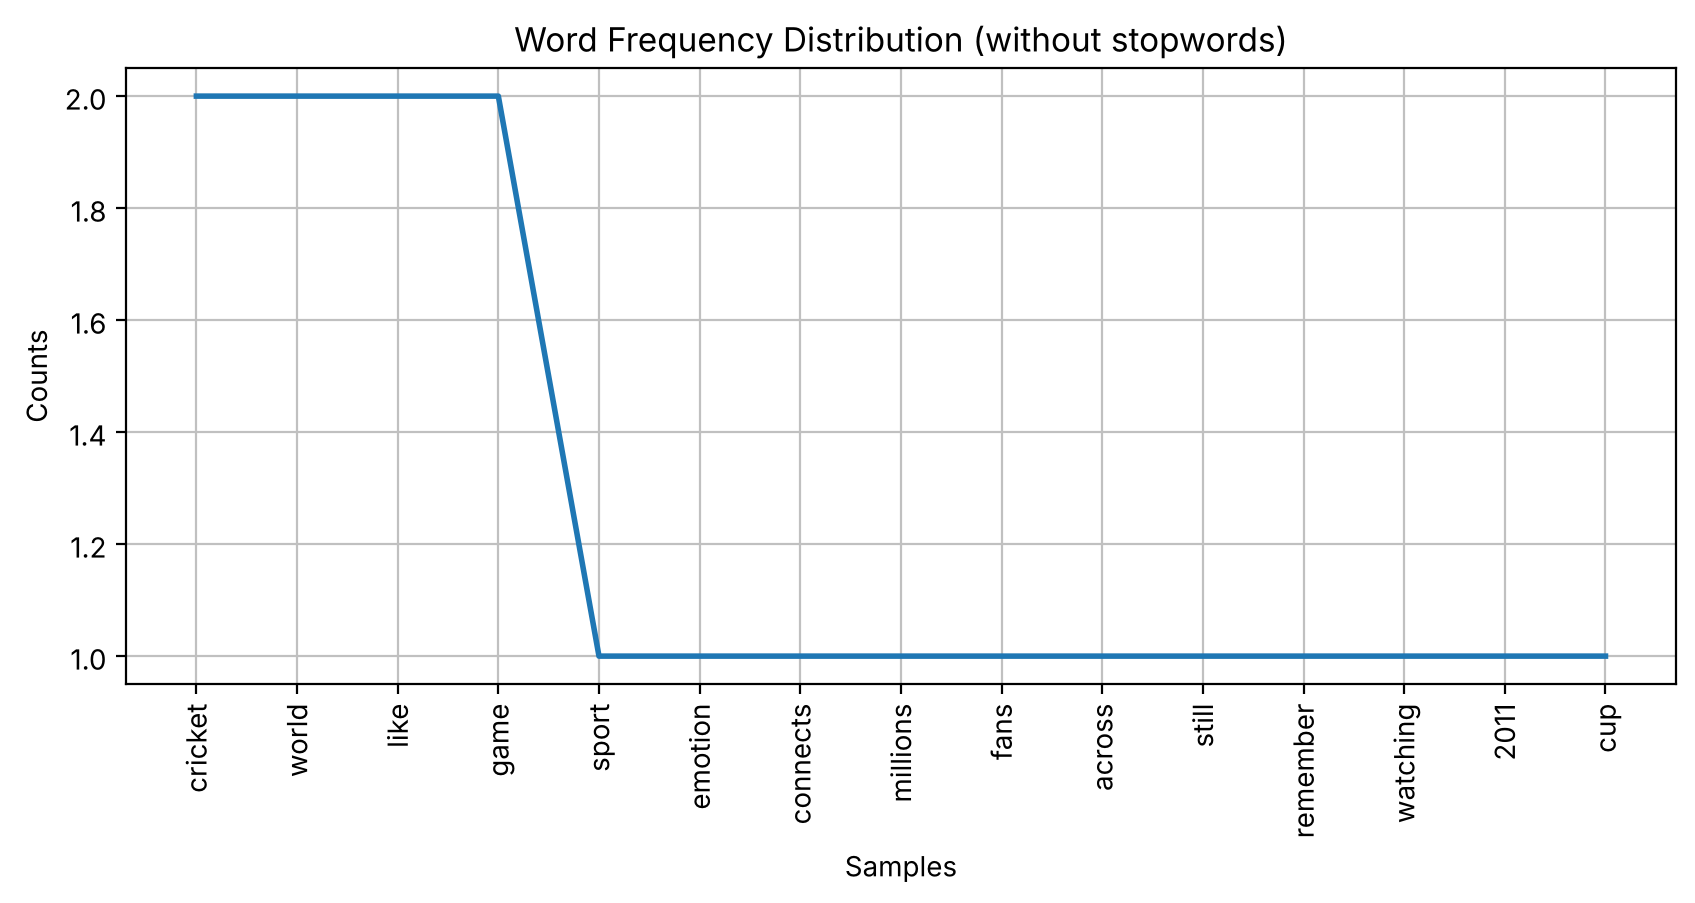

In [6]:
# 5. Word frequency distribution (excluding stopwords)
fdist = FreqDist(filtered_words)
print(fdist.most_common(10))

plt.figure(figsize=(10, 4))
fdist.plot(15, title="Word Frequency Distribution (without stopwords)")
plt.show()

## Ans 2

In [7]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

# 1. Extract alphabetic words only using re.findall()
alpha_words = re.findall(r"[a-zA-Z]+", paragraph.lower())
print(len(alpha_words), alpha_words)

110 ['cricket', 'is', 'more', 'than', 'just', 'a', 'sport', 'for', 'me', 'it', 'is', 'an', 'emotion', 'that', 'connects', 'millions', 'of', 'fans', 'across', 'the', 'world', 'i', 'still', 'remember', 'watching', 'the', 'world', 'cup', 'final', 'with', 'my', 'family', 'and', 'the', 'roar', 'of', 'the', 'crowd', 'gave', 'me', 'goosebumps', 'batsmen', 'like', 'virat', 'kohli', 'play', 'with', 'so', 'much', 'passion', 'and', 'discipline', 'that', 'every', 'match', 'feels', 'like', 'a', 'story', 'bowlers', 'work', 'hard', 'to', 'craft', 'clever', 'spells', 'and', 'a', 'single', 'wicket', 'can', 'change', 'the', 'entire', 'game', 'in', 'minutes', 'playing', 'cricket', 'with', 'my', 'friends', 'in', 'the', 'evening', 'is', 'the', 'best', 'way', 'to', 'relax', 'after', 'a', 'long', 'day', 'of', 'studies', 'this', 'amazing', 'game', 'teaches', 'teamwork', 'patience', 'and', 'the', 'courage', 'to', 'never', 'give', 'up']


In [8]:
# 2. Remove stopwords
q2_words = [w for w in alpha_words if w not in stop_words]
print(len(q2_words), q2_words)

62 ['cricket', 'sport', 'emotion', 'connects', 'millions', 'fans', 'across', 'world', 'still', 'remember', 'watching', 'world', 'cup', 'final', 'family', 'roar', 'crowd', 'gave', 'goosebumps', 'batsmen', 'like', 'virat', 'kohli', 'play', 'much', 'passion', 'discipline', 'every', 'match', 'feels', 'like', 'story', 'bowlers', 'work', 'hard', 'craft', 'clever', 'spells', 'single', 'wicket', 'change', 'entire', 'game', 'minutes', 'playing', 'cricket', 'friends', 'evening', 'best', 'way', 'relax', 'long', 'day', 'studies', 'amazing', 'game', 'teaches', 'teamwork', 'patience', 'courage', 'never', 'give']


In [9]:
# 3. Stemming
ps = PorterStemmer()
stemmed = [ps.stem(w) for w in q2_words]
print(stemmed)

['cricket', 'sport', 'emot', 'connect', 'million', 'fan', 'across', 'world', 'still', 'rememb', 'watch', 'world', 'cup', 'final', 'famili', 'roar', 'crowd', 'gave', 'goosebump', 'batsmen', 'like', 'virat', 'kohli', 'play', 'much', 'passion', 'disciplin', 'everi', 'match', 'feel', 'like', 'stori', 'bowler', 'work', 'hard', 'craft', 'clever', 'spell', 'singl', 'wicket', 'chang', 'entir', 'game', 'minut', 'play', 'cricket', 'friend', 'even', 'best', 'way', 'relax', 'long', 'day', 'studi', 'amaz', 'game', 'teach', 'teamwork', 'patienc', 'courag', 'never', 'give']


In [10]:
# 4. Lemmatization
lem = WordNetLemmatizer()
lemmatized = [lem.lemmatize(w) for w in q2_words]            # default POS = noun
lemmatized_v = [lem.lemmatize(w, pos="v") for w in q2_words] # treating words as verbs
print(lemmatized)
print(lemmatized_v)

['cricket', 'sport', 'emotion', 'connects', 'million', 'fan', 'across', 'world', 'still', 'remember', 'watching', 'world', 'cup', 'final', 'family', 'roar', 'crowd', 'gave', 'goosebump', 'batsman', 'like', 'virat', 'kohli', 'play', 'much', 'passion', 'discipline', 'every', 'match', 'feel', 'like', 'story', 'bowler', 'work', 'hard', 'craft', 'clever', 'spell', 'single', 'wicket', 'change', 'entire', 'game', 'minute', 'playing', 'cricket', 'friend', 'evening', 'best', 'way', 'relax', 'long', 'day', 'study', 'amazing', 'game', 'teach', 'teamwork', 'patience', 'courage', 'never', 'give']
['cricket', 'sport', 'emotion', 'connect', 'millions', 'fan', 'across', 'world', 'still', 'remember', 'watch', 'world', 'cup', 'final', 'family', 'roar', 'crowd', 'give', 'goosebumps', 'batsmen', 'like', 'virat', 'kohli', 'play', 'much', 'passion', 'discipline', 'every', 'match', 'feel', 'like', 'story', 'bowlers', 'work', 'hard', 'craft', 'clever', 'spell', 'single', 'wicket', 'change', 'entire', 'game', 

In [11]:
# 5. Comparison
import pandas as pd
df = pd.DataFrame({"Original": q2_words, "Stemmed": stemmed, "Lemmatized (noun)": lemmatized, "Lemmatized (verb)": lemmatized_v})
print(df[(df.Original != df.Stemmed) | (df.Original != df["Lemmatized (verb)"])].drop_duplicates().to_string(index=False))

  Original   Stemmed Lemmatized (noun) Lemmatized (verb)
   emotion      emot           emotion           emotion
  connects   connect          connects           connect
  millions   million           million          millions
      fans       fan               fan               fan
  remember    rememb          remember          remember
  watching     watch          watching             watch
    family    famili            family            family
      gave      gave              gave              give
goosebumps goosebump         goosebump        goosebumps
discipline disciplin        discipline        discipline
     every     everi             every             every
     feels      feel              feel              feel
     story     stori             story             story
   bowlers    bowler            bowler           bowlers
    spells     spell             spell             spell
    single     singl            single            single
    change     chang           

**Explanation:** Stemming chops suffixes using fixed rules, so it is very fast but the output may not be a real word (e.g. `emotion -> emot`, `discipline -> disciplin`, `amazing -> amaz`, `evening -> even`). Lemmatization uses a dictionary (WordNet) and the part of speech, so the output is always a valid word (e.g. `studies -> study`, `watching -> watch` with verb POS, `gave -> give`).

- Prefer **stemming** when speed matters and exact word form does not, e.g. search engines, information retrieval, large-scale text classification.
- Prefer **lemmatization** when meaning and readable output are important, e.g. chatbots, sentiment analysis, question answering, text generation.

## Ans 3

In [12]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "India won the cricket world cup final, and cricket fans celebrated the thrilling cricket match across the country",
    "This smartphone has an excellent camera, and the camera takes sharp photos while the battery lasts long",
    "Heavy rain and strong winds lashed the coastal city, and the heavy rain caused floods in many areas"
]
for i, t in enumerate(texts, 1):
    print(f"Text {i}: {t}")

Text 1: India won the cricket world cup final, and cricket fans celebrated the thrilling cricket match across the country
Text 2: This smartphone has an excellent camera, and the camera takes sharp photos while the battery lasts long
Text 3: Heavy rain and strong winds lashed the coastal city, and the heavy rain caused floods in many areas


In [13]:
# 1. Bag of Words
cv = CountVectorizer(stop_words="english")
bow = cv.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
print("Vocabulary size:", len(cv.get_feature_names_out()))
bow_df

Vocabulary size: 30


,areas,battery,camera,caused,celebrated,city,coastal,country,cricket,cup,...,photos,rain,sharp,smartphone,strong,takes,thrilling,winds,won,world
Text 1,0,0,0,0,1,0,0,1,3,1,...,0,0,0,0,0,0,1,0,1,1
Text 2,0,1,2,0,0,0,0,0,0,0,...,1,0,1,1,0,1,0,0,0,0
Text 3,1,0,0,1,0,1,1,0,0,0,...,0,2,0,0,1,0,0,1,0,0


In [14]:
# 2. TF-IDF
tv = TfidfVectorizer(stop_words="english")
tfidf = tv.fit_transform(texts)
tfidf_df = pd.DataFrame(tfidf.toarray().round(3), columns=tv.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
tfidf_df

,areas,battery,camera,caused,celebrated,city,coastal,country,cricket,cup,...,photos,rain,sharp,smartphone,strong,takes,thrilling,winds,won,world
Text 1,0.00,0.000,0.000,0.00,0.229,0.00,0.00,0.229,0.688,0.229,...,0.000,0.0,0.000,0.000,0.00,0.000,0.229,0.00,0.229,0.229
Text 2,0.00,0.289,0.577,0.00,0.000,0.00,0.00,0.000,0.000,0.000,...,0.289,0.0,0.289,0.289,0.00,0.289,0.000,0.00,0.000,0.000
Text 3,0.25,0.000,0.000,0.25,0.000,0.25,0.25,0.000,0.000,0.000,...,0.000,0.5,0.000,0.000,0.25,0.000,0.000,0.25,0.000,0.000


In [15]:
# 3. Top 3 keywords per text
features = tv.get_feature_names_out()
for i in range(len(texts)):
    row = tfidf[i].toarray().ravel()
    top = row.argsort()[::-1][:3]
    print(f"Text {i+1}: ", [(features[j], round(float(row[j]), 3)) for j in top])

Text 1:  [('cricket', 0.688), ('world', 0.229), ('thrilling', 0.229)]
Text 2:  [('camera', 0.577), ('takes', 0.289), ('long', 0.289)]
Text 3:  [('rain', 0.5), ('heavy', 0.5), ('lashed', 0.25)]


**Interpretation:** TF-IDF gives a high score to words that are frequent in a text but rare in the other texts. The top keywords clearly capture the topic of each text: `cricket`, `world`, `thrilling` for the sports news; `camera`, `takes`, `long` for the product review (the camera is the main point of the review); and `rain`, `heavy`, `lashed` for the weather report. The repeated word (`cricket`, `camera`, `rain`) gets the highest score because it occurs many times in its own text but in none of the others.

## Ans 4

In [16]:
from sklearn.metrics.pairwise import cosine_similarity

text_ai = ("Artificial Intelligence is the simulation of human intelligence by machines. "
           "It uses algorithms and large amounts of data to learn patterns and make decisions. "
           "Machine learning and deep learning are major parts of AI. "
           "AI is used in healthcare, finance, and self driving cars to automate tasks and improve decisions.")
text_bc = ("Blockchain is a distributed digital ledger that records transactions across many computers. "
           "Each block of data is linked to the previous block using cryptography, which makes it secure. "
           "Blockchain removes the need for a central authority and is transparent. "
           "It is used in cryptocurrency, finance, and supply chains to secure data and record transactions.")

# 1. Preprocess and tokenize
def preprocess(text):
    text = re.sub(r"[^\w\s]", "", text.lower())
    tokens = word_tokenize(text)
    return [w for w in tokens if w not in stop_words]

tok_ai = preprocess(text_ai)
tok_bc = preprocess(text_bc)
print("AI tokens        :", tok_ai)
print("Blockchain tokens:", tok_bc)

AI tokens        : ['artificial', 'intelligence', 'simulation', 'human', 'intelligence', 'machines', 'uses', 'algorithms', 'large', 'amounts', 'data', 'learn', 'patterns', 'make', 'decisions', 'machine', 'learning', 'deep', 'learning', 'major', 'parts', 'ai', 'ai', 'used', 'healthcare', 'finance', 'self', 'driving', 'cars', 'automate', 'tasks', 'improve', 'decisions']
Blockchain tokens: ['blockchain', 'distributed', 'digital', 'ledger', 'records', 'transactions', 'across', 'many', 'computers', 'block', 'data', 'linked', 'previous', 'block', 'using', 'cryptography', 'makes', 'secure', 'blockchain', 'removes', 'need', 'central', 'authority', 'transparent', 'used', 'cryptocurrency', 'finance', 'supply', 'chains', 'secure', 'data', 'record', 'transactions']


In [17]:
# 2a. Jaccard similarity using sets
set_ai, set_bc = set(tok_ai), set(tok_bc)
inter, union = set_ai & set_bc, set_ai | set_bc
jaccard = len(inter) / len(union)
print("Common words:", inter)
print("Intersection:", len(inter), " Union:", len(union))
print("Jaccard Similarity:", round(jaccard, 4))

Common words: {'used', 'finance', 'data'}
Intersection: 3  Union: 54
Jaccard Similarity: 0.0556


In [18]:
# 2b. Cosine similarity using TfidfVectorizer
docs = [" ".join(tok_ai), " ".join(tok_bc)]
tfidf_q4 = TfidfVectorizer().fit_transform(docs)
cos_sim = cosine_similarity(tfidf_q4[0], tfidf_q4[1])[0][0]
print("Cosine Similarity:", round(cos_sim, 4))

Cosine Similarity: 0.0509


**Analysis:** Jaccard similarity only checks which words are shared (set overlap) and treats every word equally, ignoring how often a word occurs and how important it is. Cosine similarity with TF-IDF weights words by importance and frequency, so common/generic words (like `used`, `finance`) contribute less and topic-specific words (like `learning`, `blockchain`) matter more. Both metrics show that the two texts are quite different, but **cosine similarity with TF-IDF gives better insight** here because it accounts for word importance and works well even when texts have different lengths.

## Ans 5

In [19]:
from textblob import TextBlob
from wordcloud import WordCloud

reviews = [
    "The headphones are amazing! Sound quality is excellent and the battery lasts all day. Totally worth the price.",
    "Absolutely loved the food at this restaurant. The staff were friendly and the service was wonderful.",
    "Worst product ever. It stopped working after two days and the customer support was terrible.",
    "The delivery was very late and the packaging was damaged. I am extremely disappointed.",
    "The phone has a 6 inch screen and comes with a charger in the box.",
    "Great laptop with a fantastic display and fast performance. I am very happy with this purchase.",
    "The hotel room was dirty and the staff was rude. Awful experience, I would never stay here again.",
    "The package arrived on Tuesday and contains the charger and a manual.",
]

# 1 & 2. Polarity, subjectivity and classification
rows = []
for r in reviews:
    blob = TextBlob(r)
    pol, sub = blob.sentiment.polarity, blob.sentiment.subjectivity
    label = "Positive" if pol > 0.1 else "Negative" if pol < -0.1 else "Neutral"
    rows.append([r[:60] + "...", round(pol, 3), round(sub, 3), label])

result = pd.DataFrame(rows, columns=["Review", "Polarity", "Subjectivity", "Sentiment"])
result

,Review,Polarity,Subjectivity,Sentiment
0,The headphones are amazing! Sound quality is e...,0.613,0.600,Positive
1,Absolutely loved the food at this restaurant. ...,0.692,0.767,Positive
2,Worst product ever. It stopped working after t...,-1.000,1.000,Negative
3,The delivery was very late and the packaging w...,-0.570,0.765,Negative
4,The phone has a 6 inch screen and comes with a...,0.000,0.000,Neutral
5,Great laptop with a fantastic display and fast...,0.600,0.812,Positive
6,The hotel room was dirty and the staff was rud...,-0.633,0.800,Negative
7,The package arrived on Tuesday and contains th...,0.000,0.000,Neutral


In [20]:
# Same analysis with VADER (for comparison)
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()
for r in reviews:
    c = vader.polarity_scores(r)["compound"]
    lab = "Positive" if c >= 0.05 else "Negative" if c <= -0.05 else "Neutral"
    print(f"{c:+.3f}  {lab:9s} | {r[:70]}")

+0.875  Positive  | The headphones are amazing! Sound quality is excellent and the battery
+0.902  Positive  | Absolutely loved the food at this restaurant. The staff were friendly 
-0.751  Negative  | Worst product ever. It stopped working after two days and the customer
-0.743  Negative  | The delivery was very late and the packaging was damaged. I am extreme
+0.000  Neutral   | The phone has a 6 inch screen and comes with a charger in the box.
+0.913  Positive  | Great laptop with a fantastic display and fast performance. I am very 
-0.836  Negative  | The hotel room was dirty and the staff was rude. Awful experience, I w
+0.000  Neutral   | The package arrived on Tuesday and contains the charger and a manual.


Positive reviews: 3


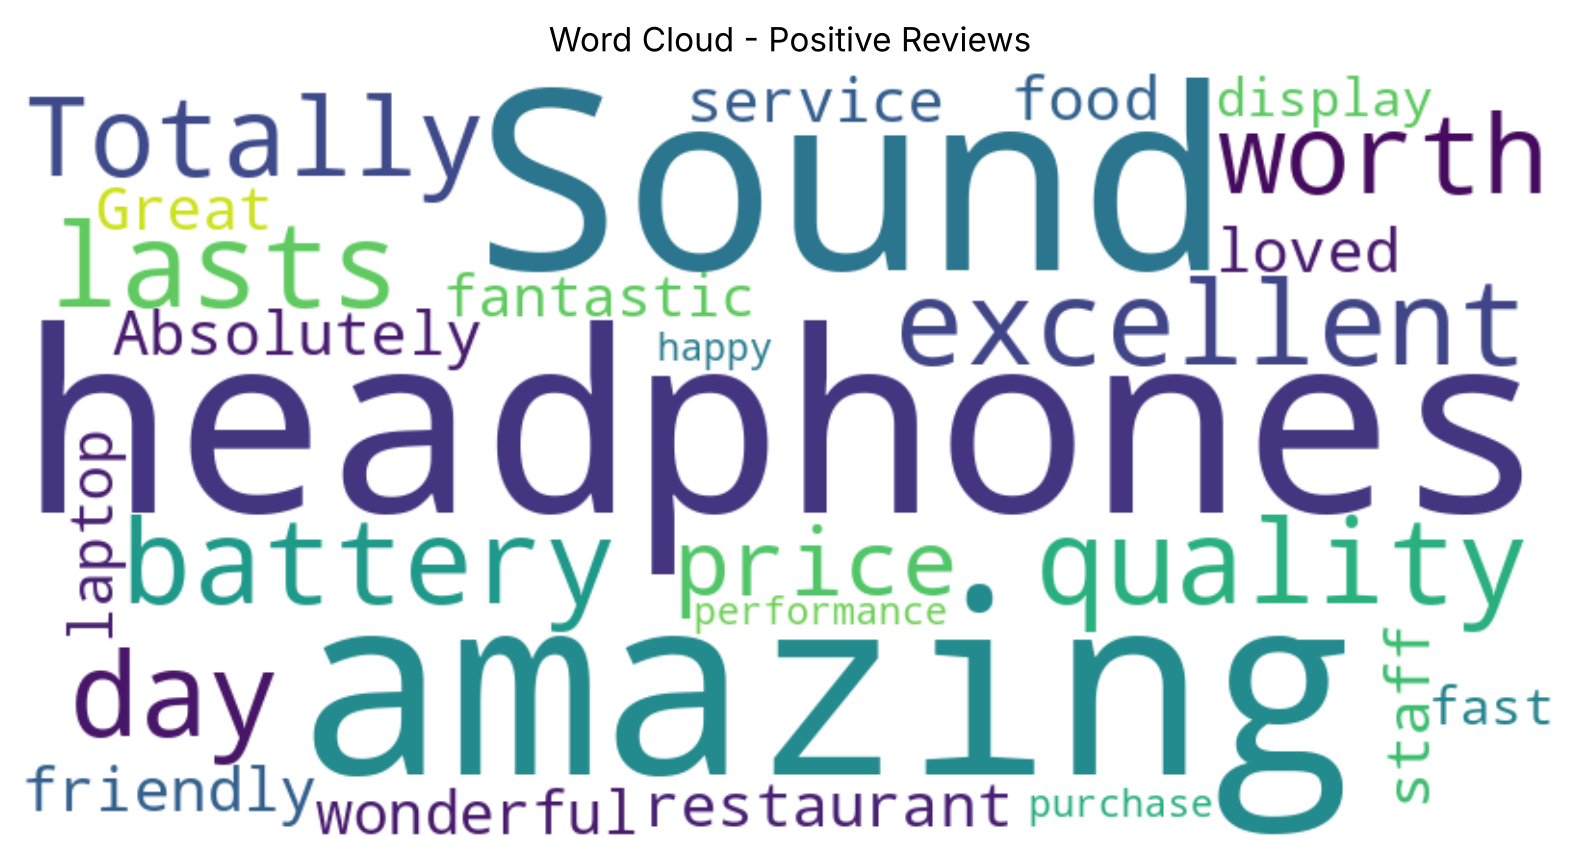

In [21]:
# 3. Word cloud of positive reviews
positive_reviews = [r for r, s in zip(reviews, result["Sentiment"]) if s == "Positive"]
print("Positive reviews:", len(positive_reviews))
wc = WordCloud(width=800, height=400, background_color="white", stopwords=set(stopwords.words("english"))).generate(" ".join(positive_reviews))
plt.figure(figsize=(10, 5))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud - Positive Reviews")
plt.show()

## Ans 6

In [22]:
import numpy as np, random, os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical

np.random.seed(42); random.seed(42); tf.random.set_seed(42)

data = ("Technology is changing the way we live and work every day. "
        "Computers help us solve problems faster and connect with people around the world. "
        "Artificial intelligence can learn from data and make smart decisions. "
        "Students use technology to learn new skills and share ideas online. "
        "Machine learning models can write text and answer questions. "
        "The future of technology looks bright and full of new possibilities. "
        "We must use technology wisely to make life better for everyone.")
print(len(data.split()), "words")

76 words


In [23]:
# 1. Tokenize using keras Tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts([data])
total_words = len(tokenizer.word_index) + 1
print("Vocabulary size:", total_words)
print(dict(list(tokenizer.word_index.items())[:10]))

Vocabulary size: 59
{'and': 1, 'technology': 2, 'the': 3, 'we': 4, 'can': 5, 'learn': 6, 'make': 7, 'use': 8, 'to': 9, 'new': 10}


In [24]:
# 2. Create input sequences (n-gram sequences, sentence by sentence)
input_sequences = []
for line in data.split("."):
    if line.strip() == "":
        continue
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

max_len = max(len(s) for s in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding="pre")
X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = to_categorical(y, num_classes=total_words)
print("Total sequences:", len(input_sequences), " X shape:", X.shape, " y shape:", y.shape)

# Build LSTM model
model = Sequential([
    Embedding(total_words, 64),
    LSTM(100),
    Dense(total_words, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.build(input_shape=(None, max_len - 1))
model.summary()

Total sequences: 69  X shape: (69, 12)  y shape: (69, 59)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 12, 64)         │         3,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 100)            │        66,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 59)             │         5,959 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 75,735 (295.84 KB)

 Trainable params: 75,735 (295.84 KB)

 Non-trainable params: 0 (0.00 B)

Final loss: 0.0525  Final accuracy: 1.0


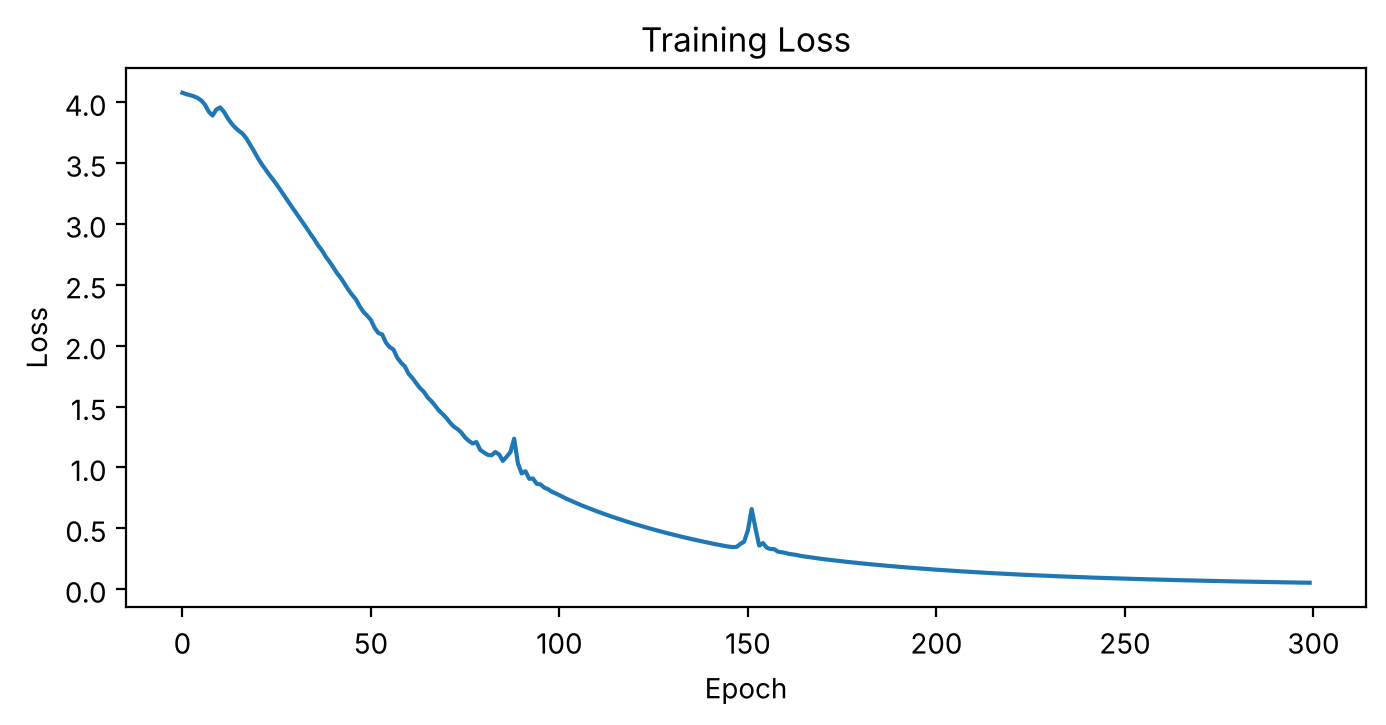

In [25]:
# 3. Train the model
history = model.fit(X, y, epochs=300, verbose=0)
print("Final loss:", round(history.history["loss"][-1], 4), " Final accuracy:", round(history.history["accuracy"][-1], 4))

plt.figure(figsize=(8, 3.5))
plt.plot(history.history["loss"]); plt.title("Training Loss"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.show()

In [26]:
# Generate new lines from a seed word
index_word = {v: k for k, v in tokenizer.word_index.items()}

def generate_text(seed, next_words=8):
    text = seed
    for _ in range(next_words):
        seq = tokenizer.texts_to_sequences([text])[0]
        seq = pad_sequences([seq], maxlen=max_len - 1, padding="pre")
        pred = model.predict(seq, verbose=0)[0]
        text += " " + index_word.get(int(np.argmax(pred)), "")
    return text

for seed in ["technology", "machine", "students"]:
    print(generate_text(seed))

technology is changing the way we live and work


machine learning models can write text and answer questions


students use technology to learn new skills and share
